# 05 Ensemble and final evaluation

**Notebook 5 of 6, xBD building damage assessment**

Two parts:

**A** combines the three five class models into an ensemble by averaging their
class probabilities and taking the maximum. No stacking, no learned weighting.

**B** drops every convenience of the tile based evaluation used so far. All images
of the holdout split are scored at full 1024x1024 size, without any filtering, using a sliding
window that is stitched back together, and the official xView2 formula

```
score = 0.3 * F1_localization + 0.7 * F1_damage
```

where `F1_damage` is the harmonic mean of the F1 values of the four damage
classes. This weighting appears only in this notebook; notebooks 2 to 4 work
with per class precision, recall and F1 throughout.

Requires the checkpoints from notebooks 2 to 4, `val_tiles/val_damage_raw_tiles_all_events.pt`
and the holdout split of xBD.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

from collections import Counter

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
from matplotlib.patches import Patch
import torch
from torch.utils.data import Dataset, DataLoader

import config
from common import data, crops, models, losses, train, evaluate, plots

pl.rcParams["figure.dpi"] = 120
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

paths = data.resolve_splits(config.DATA_ROOT)
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
print("data root:", config.DATA_ROOT)
for split in config.SPLIT_FOLDERS:
    if split not in paths:
        print(f"{split}: not found, skipped")
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


/DATA/schrepel/ml_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
data root: /DATA/schrepel/xbd_new/data
train: 2746 pre-disaster images
test: 917 pre-disaster images
hold: 933 pre-disaster images
tier3: 6288 pre-disaster images


## 1. Models

In [2]:
EVAL_SPLIT = "hold"
N_EVAL_IMAGES = None   # images in the final evaluation, None means all

model_localization = models.UNet(in_channels=3, out_channels=2, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_localization, "unet_localization_best.pt", device)

model_unet = models.UNet(in_channels=6, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_unet, "damage_5class_best.pt", device)

model_siamese = models.SiameseUNet(in_channels=3, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_siamese, "damage_siamese_best.pt", device)

model_resnet = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                 encoder_weights=None).to(device)
train.load_checkpoint(model_resnet, "damage_siamese_resnet_best.pt", device)

# name -> (model, expects six stacked channels, needs ImageNet normalization)
DAMAGE_MODELS = {
    "U-Net (stacked)":  (model_unet, True, False),
    "Siamese U-Net":    (model_siamese, False, False),
    "Siamese ResNet50": (model_resnet, False, True),
}

loaded /DATA/schrepel/xbd_new/checkpoints/unet_localization_best.pt


loaded /DATA/schrepel/xbd_new/checkpoints/damage_5class_best.pt


loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_best.pt


loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_resnet_best.pt


## 2. Shared helpers

One wrapper over the two calling conventions (stacked input versus two separate
inputs) so the ensemble and the evaluation can treat all models alike. All
metrics are pixel based, whereas the official competition scores per building
polygon.

In [3]:
def damage_probs(model, is_stacked, needs_norm, pre_batch, post_batch):
    """The ImageNet pretrained encoder expects normalized inputs, the others do not."""
    if needs_norm:
        mean, std = crops.IMAGENET_MEAN.to(pre_batch.device), crops.IMAGENET_STD.to(pre_batch.device)
        pre_batch, post_batch = (pre_batch - mean) / std, (post_batch - mean) / std

    logits = (model(torch.cat([pre_batch, post_batch], dim=1)) if is_stacked
              else model(pre_batch, post_batch))
    return torch.softmax(logits, dim=1)

## Part A: ensemble on the fixed validation tiles

Same basis as notebooks 3 and 4, so the effect of the ensemble is visible
independently of the switch to full images in part B.

In [4]:
class RawTileDataset(Dataset):
    def __init__(self, raw_tiles, target_fn=crops.damage_identity):
        self.raw_tiles = raw_tiles
        self.target_fn = target_fn

    def __len__(self):
        return len(self.raw_tiles)

    def __getitem__(self, index):
        pre_tile, post_tile, target_tile, _ = self.raw_tiles[index]
        target = torch.from_numpy(self.target_fn(target_tile).copy()).long()
        return crops.to_chw(pre_tile), crops.to_chw(post_tile), target


val_tiles_all = train.load_val_tiles("val_damage_raw_tiles_all_events.pt")
val_loader = DataLoader(RawTileDataset(val_tiles_all), batch_size=16, shuffle=False)

loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles_all_events.pt (8112 tiles)


In [5]:
def evaluate_on_tiles(loader, models, device, n_classes=5):
    """Scores every model and the ensemble in a single pass."""
    counters = {name: evaluate.ConfusionCounter(n_classes) for name in models}
    counters["ensemble"] = evaluate.ConfusionCounter(n_classes)

    for model, *_ in models.values():
        model.eval()

    with torch.no_grad():
        for pre, post, targets in loader:
            pre, post = pre.to(device), post.to(device)
            targets_np = targets.numpy()

            total = None
            for name, (model, is_stacked, needs_norm) in models.items():
                probs = damage_probs(model, is_stacked, needs_norm, pre, post)
                total = probs if total is None else total + probs
                counters[name].update(probs.argmax(dim=1).cpu().numpy(), targets_np)

            counters["ensemble"].update((total / len(models)).argmax(dim=1).cpu().numpy(), targets_np)

    return {name: counter.per_class() for name, counter in counters.items()}


results_tiles = evaluate_on_tiles(val_loader, DAMAGE_MODELS, device)

for name, results in results_tiles.items():
    evaluate.print_metrics(results, config.FIVE_CLASS_NAMES, name)
    print()

U-Net (stacked)
       class   precision    recall      F1
  background       0.977     0.984   0.980
   no-damage       0.820     0.780   0.800
       minor       0.427     0.399   0.413
       major       0.639     0.592   0.615
   destroyed       0.737     0.667   0.700

Siamese U-Net
       class   precision    recall      F1
  background       0.979     0.986   0.983
   no-damage       0.841     0.788   0.813
       minor       0.448     0.424   0.436
       major       0.601     0.631   0.616
   destroyed       0.759     0.690   0.723

Siamese ResNet50
       class   precision    recall      F1
  background       0.979     0.986   0.982
   no-damage       0.844     0.780   0.811
       minor       0.432     0.486   0.457
       major       0.664     0.662   0.663
   destroyed       0.803     0.667   0.729

ensemble
       class   precision    recall      F1
  background       0.979     0.988   0.983
   no-damage       0.852     0.803   0.827
       minor       0.509     0.445   0

In [6]:
header = f"{'model':<20s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in range(5)) + f"{'mean 1 to 4':>13s}"
print("F1 per class")
print(header)
for name, results in results_tiles.items():
    f1s = [results[c][2] for c in range(5)]
    print(f"{name:<20s}" + "".join(f"{f:>12.3f}" for f in f1s) + f"{np.mean(f1s[1:]):>13.3f}")

F1 per class
model                 background   no-damage       minor       major   destroyed  mean 1 to 4
U-Net (stacked)            0.980       0.800       0.413       0.615       0.700        0.632
Siamese U-Net              0.983       0.813       0.436       0.616       0.723        0.647
Siamese ResNet50           0.982       0.811       0.457       0.663       0.729        0.665
ensemble                   0.983       0.827       0.475       0.663       0.740        0.676


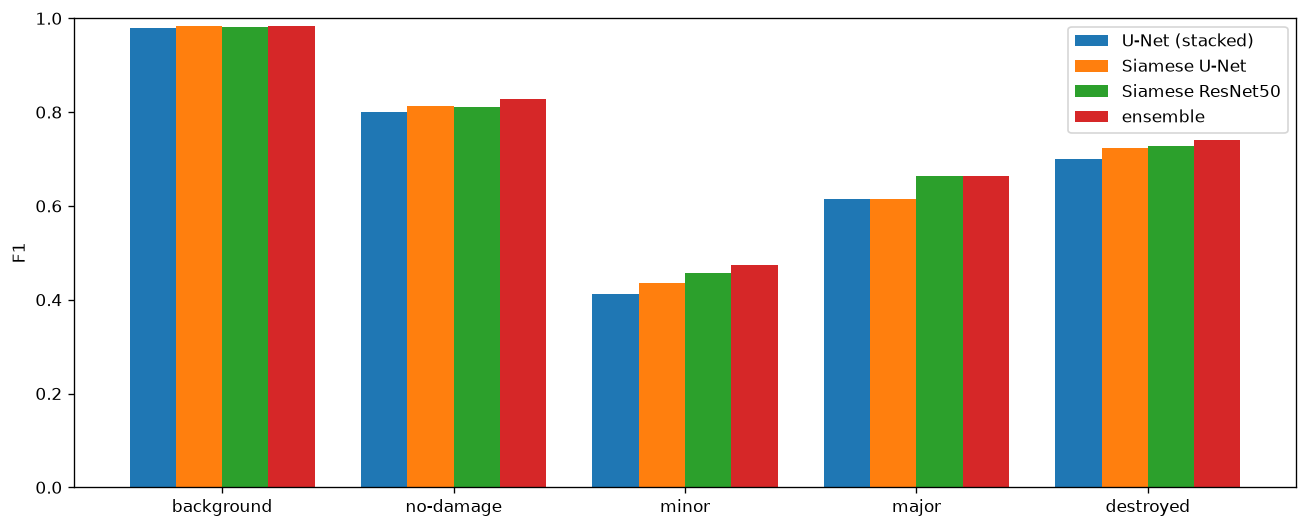

In [7]:
names = list(results_tiles)
x = np.arange(5)
width = 0.8 / len(names)

pl.figure(figsize=(11, 4.5))
for i, name in enumerate(names):
    offset = (i - (len(names) - 1) / 2) * width
    pl.bar(x + offset, [results_tiles[name][c][2] for c in range(5)], width,
           label=name, color="C3" if name == "ensemble" else f"C{i}")

pl.xticks(x, [config.FIVE_CLASS_NAMES[c] for c in range(5)])
pl.ylabel("F1")
pl.ylim(0, 1)
pl.legend()
pl.tight_layout()
pl.show()

## Part B: full images of the holdout split

Part A and notebooks 2 to 4 score the models on crops from the test split, which
acted as the validation set during development: it selected the checkpoints and
the variants, so numbers taken from it are not a clean estimate of the final
quality. Part B therefore evaluates on the holdout split of xBD, which was never
used for any decision.

| | part A and notebooks 2 to 4 | part B |
|---|---|---|
| split | test (validation) | hold (untouched) |
| basis | 256x256 crops | full 1024x1024 images |
| selection | images above 0.1% building area, crops biased towards buildings | every image, unfiltered |
| prediction | directly on the crop | sliding window, stitched back together |
| metric | F1 per class | 0.3 localization plus 0.7 damage |

`F1_localization` comes from UNet1 on the pre image against the pre target,
`F1_damage` from the five class model on the post image against the post target.

In [8]:
eval_stems = [f.replace("_pre_disaster.png", "") for f in file_lists[EVAL_SPLIT]]
if N_EVAL_IMAGES is not None:
    eval_stems = eval_stems[:N_EVAL_IMAGES]

eval_image_dir, eval_target_dir = paths[EVAL_SPLIT]["images"], paths[EVAL_SPLIT]["targets"]

print(f"{EVAL_SPLIT} split: {len(eval_stems)} images over "
      f"{len(Counter(s.split('_')[0] for s in eval_stems))} events")

hold split: 933 images over 10 events


In [9]:
def predict_full_image(pre_image, post_image, models, localization_model,
                       n_classes=5, device="cpu", batch_size=8):
    """Sliding window over one image pair for all models at once.

    Returns a class map per damage model plus the ensemble, and the building
    mask from the localization model, all at the original image size.
    """
    pre_t, post_t = crops.to_chw(pre_image), crops.to_chw(post_image)
    _, height, width = pre_t.shape

    prob_maps = {name: torch.zeros(n_classes, height, width) for name in models}
    prob_maps["ensemble"] = torch.zeros(n_classes, height, width)
    building_map = torch.zeros(height, width)
    count_map = torch.zeros(height, width)
    positions = evaluate.tile_positions(height, width)

    with torch.no_grad():
        for i in range(0, len(positions), batch_size):
            chunk = positions[i:i + batch_size]
            pre_batch = torch.stack([pre_t[:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE]
                                     for r, c in chunk]).to(device)
            post_batch = torch.stack([post_t[:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE]
                                      for r, c in chunk]).to(device)

            total = None
            for name, (model, is_stacked, needs_norm) in models.items():
                probs = damage_probs(model, is_stacked, needs_norm, pre_batch, post_batch)
                total = probs if total is None else total + probs
                for (r, c), p in zip(chunk, probs.cpu()):
                    prob_maps[name][:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += p

            for (r, c), p in zip(chunk, (total / len(models)).cpu()):
                prob_maps["ensemble"][:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += p

            building_probs = torch.softmax(localization_model(pre_batch), dim=1)[:, 1].cpu()
            for (r, c), p in zip(chunk, building_probs):
                building_map[r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += p
                count_map[r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += 1

    count_map[count_map == 0] = 1
    predictions = {name: (pm / count_map.unsqueeze(0)).argmax(0).numpy().astype(np.uint8)
                   for name, pm in prob_maps.items()}
    building_mask = ((building_map / count_map) > 0.5).numpy().astype(np.uint8)

    return predictions, building_mask

In [10]:
def run_full_image_evaluation(stems, models, localization_model, device, report_every=100):
    """Damage counts per model, plus two kinds of localisation counts.

    localization_counter holds the building mask of the localisation U-Net, which
    is the mask used for the submission in the challenge. own_counters hold the
    building mask of every damage model itself, which is everything it predicts
    as class 1 or higher.
    """
    damage_counters = {name: evaluate.ConfusionCounter(5) for name in list(models) + ["ensemble"]}
    own_counters = {name: evaluate.ConfusionCounter(2) for name in list(models) + ["ensemble"]}
    localization_counter = evaluate.ConfusionCounter(2)

    for model, *_ in models.values():
        model.eval()
    localization_model.eval()

    image_dir, target_dir = eval_image_dir, eval_target_dir

    for i, stem in enumerate(stems, start=1):
        pre_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_pre_disaster.png")))
        post_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_post_disaster.png")))
        pre_target = np.array(Image.open(os.path.join(target_dir, f"{stem}_pre_disaster_target.png")))
        post_target = np.array(Image.open(os.path.join(target_dir, f"{stem}_post_disaster_target.png")))

        predictions, building_mask = predict_full_image(
            pre_image, post_image, models, localization_model, device=device)

        buildings = (pre_target > 0).astype(np.uint8)
        localization_counter.update(building_mask, buildings)
        for name, prediction in predictions.items():
            damage_counters[name].update(prediction, post_target)
            own_counters[name].update((prediction >= 1).astype(np.uint8), buildings)

        if i % report_every == 0 or i == len(stems):
            print(f"{i}/{len(stems)} images")

    return damage_counters, localization_counter, own_counters


done = config.RESULTS_DIR / "full_image_evaluation.json"
if done.exists():
    saved = evaluate.load_counters(done)
    damage_counters = saved["damage"]
    localization_counter = saved["localization"]
    own_counters = saved["own"]
    print(f"loaded {done}")
else:
    damage_counters, localization_counter, own_counters = run_full_image_evaluation(
        eval_stems, DAMAGE_MODELS, model_localization, device)
    evaluate.save_counters(done, {
        "damage": damage_counters,
        "localization": localization_counter,
        "own": own_counters})

loaded /DATA/schrepel/xbd_new/results/full_image_evaluation.json


In [11]:
p_loc, r_loc, f1_localization = localization_counter.per_class()[1]
print(f"localization U-Net: precision {p_loc:.3f}, recall {r_loc:.3f}, F1 {f1_localization:.3f}")

print("\nbuilding mask of the damage models themselves (class 1 and above)")
print(f"{'model':<20s}{'precision':>12s}{'recall':>10s}{'F1':>8s}")
for name, counter in own_counters.items():
    p, r, f1 = counter.per_class()[1]
    print(f"{name:<20s}{p:>12.3f}{r:>10.3f}{f1:>8.3f}")

localization U-Net: precision 0.886, recall 0.839, F1 0.862

building mask of the damage models themselves (class 1 and above)
model                  precision    recall      F1
U-Net (stacked)            0.877     0.815   0.845
Siamese U-Net              0.888     0.835   0.861
Siamese ResNet50           0.888     0.829   0.857
ensemble                   0.900     0.830   0.864


In [12]:
final_results = {}
for name, counter in damage_counters.items():
    per_class = counter.per_class()
    f1_damage, score = evaluate.xview2_score(per_class, f1_localization)
    final_results[name] = {"per_class": per_class, "f1_damage": f1_damage, "score": score}

for name, entry in final_results.items():
    evaluate.print_metrics(entry["per_class"], config.FIVE_CLASS_NAMES, name)
    print(f"  F1 damage {entry['f1_damage']:.3f}, score {entry['score']:.3f}\n")

U-Net (stacked)
       class   precision    recall      F1
  background       0.988     0.992   0.990
   no-damage       0.820     0.783   0.801
       minor       0.469     0.435   0.452
       major       0.667     0.596   0.629
   destroyed       0.743     0.694   0.717
  F1 damage 0.621, score 0.693

Siamese U-Net
       class   precision    recall      F1
  background       0.990     0.993   0.991
   no-damage       0.841     0.790   0.815
       minor       0.466     0.461   0.464
       major       0.595     0.624   0.609
   destroyed       0.773     0.717   0.744
  F1 damage 0.628, score 0.698

Siamese ResNet50
       class   precision    recall      F1
  background       0.989     0.993   0.991
   no-damage       0.851     0.788   0.818
       minor       0.459     0.542   0.497
       major       0.661     0.625   0.642
   destroyed       0.809     0.686   0.742
  F1 damage 0.652, score 0.715

ensemble
       class   precision    recall      F1
  background       0.989     0.

In [13]:
header = (f"{'model':<20s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES)
          + f"{'F1 damage':>12s}{'F1 loc':>9s}{'score':>9s}")
print(header)
for name, entry in sorted(final_results.items(), key=lambda kv: -kv[1]["score"]):
    f1s = "".join(f"{entry['per_class'][c][2]:>12.3f}" for c in config.DAMAGE_CLASSES)
    print(f"{name:<20s}{f1s}{entry['f1_damage']:>12.3f}{f1_localization:>9.3f}{entry['score']:>9.3f}")

model                  no-damage       minor       major   destroyed   F1 damage   F1 loc    score
ensemble                   0.829       0.513       0.663       0.759       0.669    0.862    0.727
Siamese ResNet50           0.818       0.497       0.642       0.742       0.652    0.862    0.715
Siamese U-Net              0.815       0.464       0.609       0.744       0.628    0.862    0.698
U-Net (stacked)            0.801       0.452       0.629       0.717       0.621    0.862    0.693


### Both ways of providing the building mask

A submission consists of two images per scene, a building mask and a damage map.
Both may come from one network or from two. The table above uses the mask of the
localization U-Net, which is why `F1 loc` is the same in every row. The table
below instead takes the mask of the damage model itself, so every model provides
both images on its own.

In [14]:
header = (f"{'model':<20s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES)
          + f"{'F1 damage':>12s}{'F1 loc':>9s}{'score':>9s}")
print("building mask from the damage model itself")
print(header)

own_results = {}
for name, counter in damage_counters.items():
    per_class = counter.per_class()
    f1_own_loc = own_counters[name].per_class()[1][2]
    f1_damage, score = evaluate.xview2_score(per_class, f1_own_loc)
    own_results[name] = {"per_class": per_class, "f1_damage": f1_damage,
                         "f1_localization": f1_own_loc, "score": score}

for name, entry in sorted(own_results.items(), key=lambda kv: -kv[1]["score"]):
    f1s = "".join(f"{entry['per_class'][c][2]:>12.3f}" for c in config.DAMAGE_CLASSES)
    print(f"{name:<20s}{f1s}{entry['f1_damage']:>12.3f}{entry['f1_localization']:>9.3f}"
          f"{entry['score']:>9.3f}")

best_unet1 = max(final_results.values(), key=lambda e: e["score"])["score"]
best_own = max(own_results.values(), key=lambda e: e["score"])["score"]
print(f"\nbest score with the localization U-Net: {best_unet1:.3f}")
print(f"best score with the model's own mask:   {best_own:.3f}")

building mask from the damage model itself
model                  no-damage       minor       major   destroyed   F1 damage   F1 loc    score
ensemble                   0.829       0.513       0.663       0.759       0.669    0.864    0.727
Siamese ResNet50           0.818       0.497       0.642       0.742       0.652    0.857    0.713
Siamese U-Net              0.815       0.464       0.609       0.744       0.628    0.861    0.698
U-Net (stacked)            0.801       0.452       0.629       0.717       0.621    0.845    0.688

best score with the localization U-Net: 0.727
best score with the model's own mask:   0.727


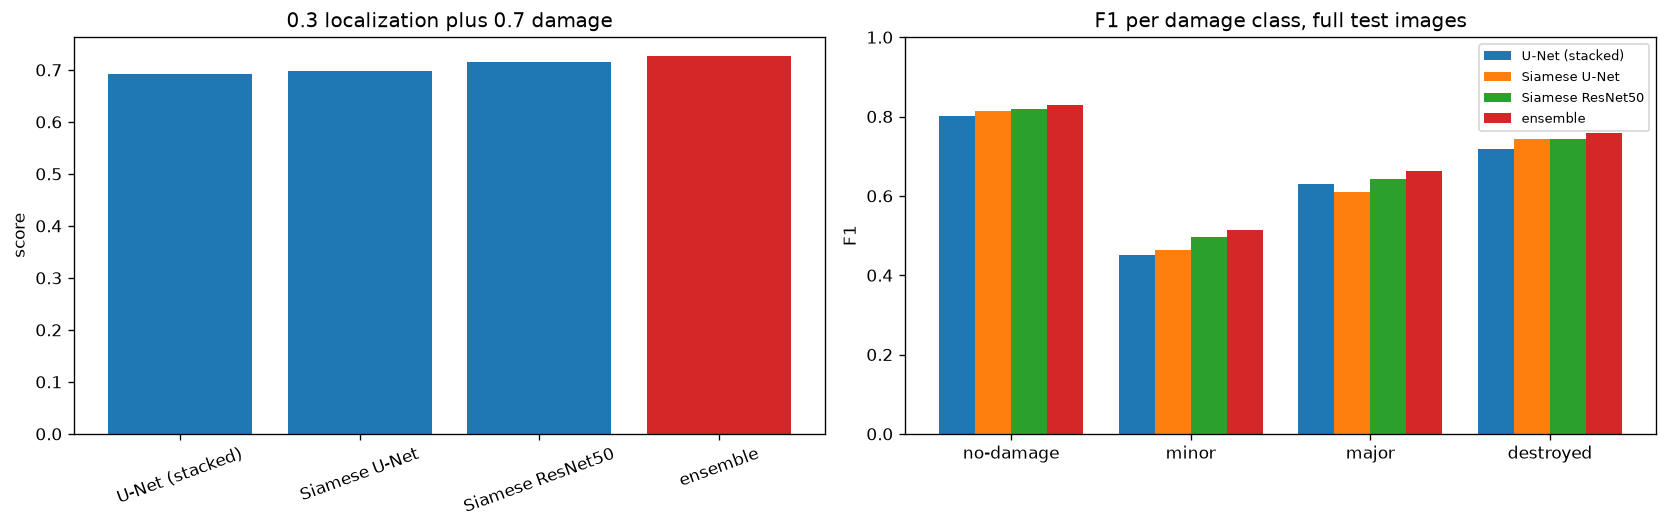

In [15]:
names = list(final_results)
fig, ax = pl.subplots(1, 2, figsize=(14, 4.5))

ax[0].bar(names, [final_results[n]["score"] for n in names],
          color=["C3" if n == "ensemble" else "C0" for n in names])
ax[0].set_ylabel("score")
ax[0].set_title("0.3 localization plus 0.7 damage")
ax[0].tick_params(axis="x", rotation=20)

x = np.arange(4)
width = 0.8 / len(names)
for i, name in enumerate(names):
    offset = (i - (len(names) - 1) / 2) * width
    ax[1].bar(x + offset, [final_results[name]["per_class"][c][2] for c in config.DAMAGE_CLASSES],
              width, label=name, color="C3" if name == "ensemble" else f"C{i}")
ax[1].set_xticks(x)
ax[1].set_xticklabels([config.FIVE_CLASS_NAMES[c] for c in config.DAMAGE_CLASSES])
ax[1].set_ylabel("F1")
ax[1].set_ylim(0, 1)
ax[1].set_title("F1 per damage class, full test images")
ax[1].legend(fontsize=8)

pl.tight_layout()
pl.show()

### Example predictions at full size

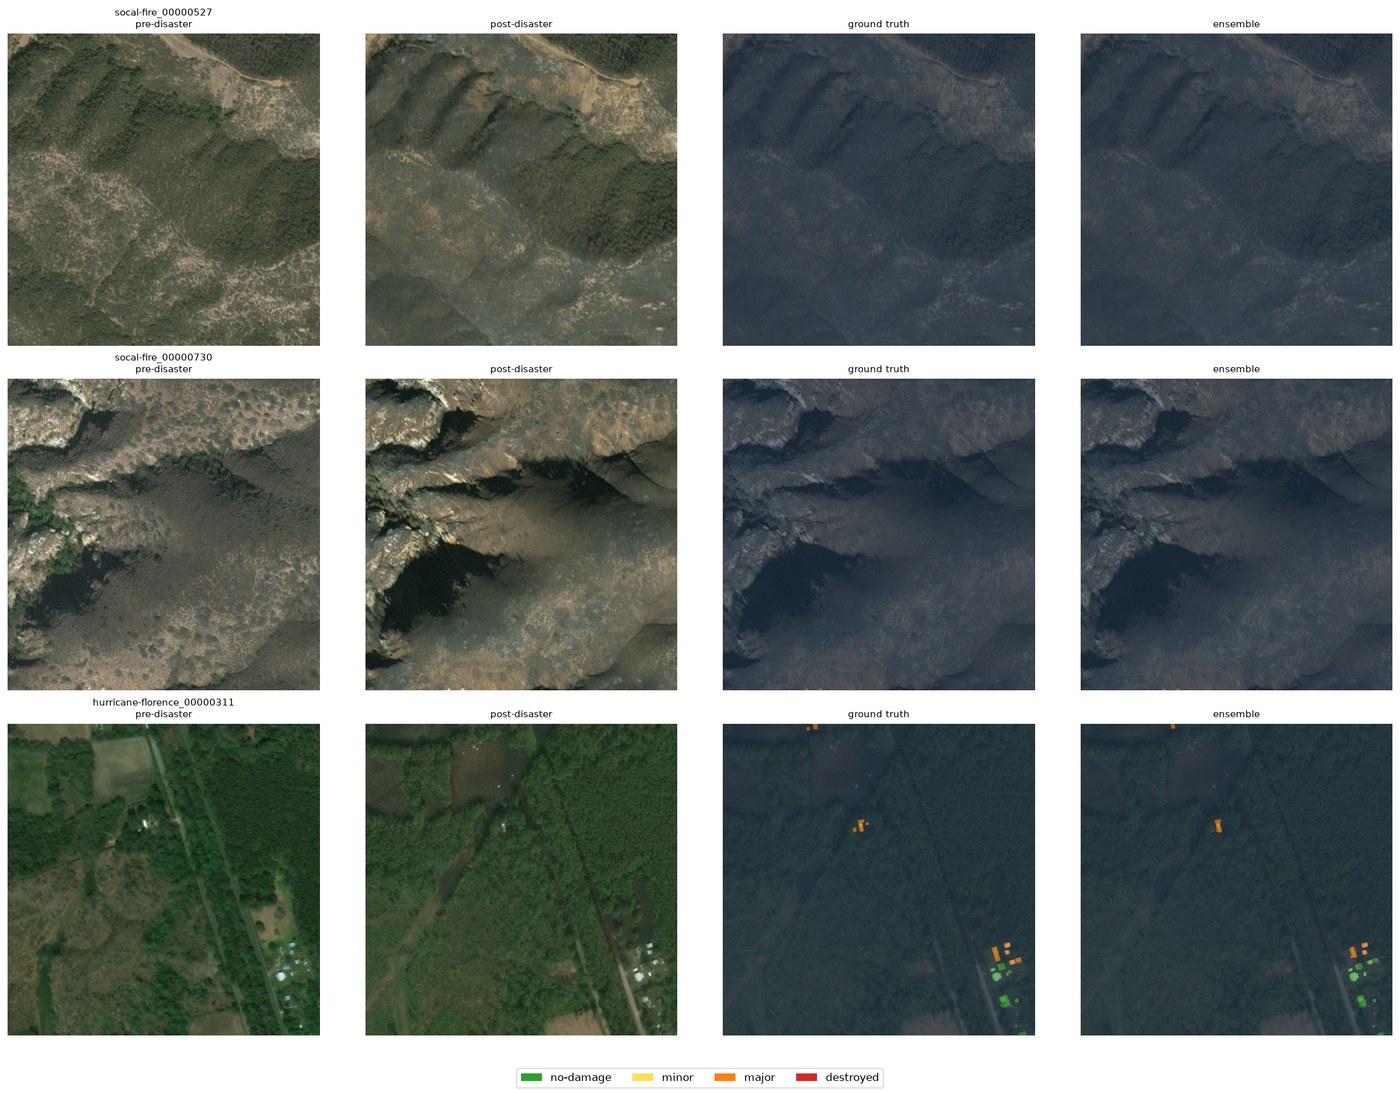

In [16]:
n_examples = min(3, len(eval_stems))
example_stems = list(np.random.choice(eval_stems, n_examples, replace=False))
legend_handles = [Patch(facecolor=plots.FIVE_CLASS_CMAP(c / 4), label=config.FIVE_CLASS_NAMES[c])
                  for c in range(1, 5)]

fig, ax = pl.subplots(n_examples, 4, figsize=(19, 4.8 * n_examples))
ax = np.atleast_2d(ax)

for row, stem in enumerate(example_stems):
    image_dir, target_dir = eval_image_dir, eval_target_dir
    pre_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_pre_disaster.png")))
    post_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_post_disaster.png")))
    post_target = np.array(Image.open(os.path.join(target_dir, f"{stem}_post_disaster_target.png")))

    predictions, _ = predict_full_image(pre_image, post_image, DAMAGE_MODELS,
                                        model_localization, device=device)

    ax[row, 0].imshow(pre_image)
    ax[row, 0].set_title(f"{stem}\npre-disaster", fontsize=9)
    ax[row, 1].imshow(post_image)
    ax[row, 1].set_title("post-disaster", fontsize=9)

    ax[row, 2].imshow(post_image)
    ax[row, 2].imshow(post_target, cmap=plots.FIVE_CLASS_CMAP, alpha=0.6, vmin=0, vmax=4)
    ax[row, 2].set_title("ground truth", fontsize=9)

    ax[row, 3].imshow(post_image)
    ax[row, 3].imshow(predictions["ensemble"], cmap=plots.FIVE_CLASS_CMAP, alpha=0.6, vmin=0, vmax=4)
    ax[row, 3].set_title("ensemble", fontsize=9)

    for a in ax[row]:
        a.axis("off")

fig.legend(handles=legend_handles, loc="lower center", ncol=4)
pl.tight_layout(rect=[0, 0.04, 1, 1])
pl.show()

## Majority vote per building region

Every connected building region in the ensemble prediction is set to its most
frequent damage class. The building mask stays unchanged, so only the damage F1
can move. Scored over all pixels as above and, for comparison, the official
way: damage only on ground truth building pixels, masked by the localization.

In [17]:
PRED_DIR = config.PRED_DIR / EVAL_SPLIT
PRED_DIR.mkdir(parents=True, exist_ok=True)

for model, *_ in DAMAGE_MODELS.values():
    model.eval()
model_localization.eval()

image_dir, target_dir = eval_image_dir, eval_target_dir

for i, stem in enumerate(eval_stems, start=1):
    if not (PRED_DIR / f"{stem}_ensemble.png").exists():
        pre_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_pre_disaster.png")))
        post_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_post_disaster.png")))

        predictions, building_mask = predict_full_image(
            pre_image, post_image, DAMAGE_MODELS, model_localization, device=device)
        Image.fromarray(predictions["ensemble"]).save(PRED_DIR / f"{stem}_ensemble.png")
        Image.fromarray(building_mask).save(PRED_DIR / f"{stem}_building.png")

    if i % 100 == 0 or i == len(eval_stems):
        print(f"{i}/{len(eval_stems)} images")

100/933 images
200/933 images
300/933 images
400/933 images
500/933 images
600/933 images
700/933 images
800/933 images
900/933 images
933/933 images


In [18]:
def score_saved_predictions(stems, transform=None):
    """Damage counters of the saved ensemble maps, over all pixels and the official way."""
    counters = {"all pixels": evaluate.ConfusionCounter(5), "official": evaluate.ConfusionCounter(5)}

    for stem in stems:
        prediction = np.array(Image.open(PRED_DIR / f"{stem}_ensemble.png"))
        building_mask = np.array(Image.open(PRED_DIR / f"{stem}_building.png"))
        post_target = np.array(Image.open(os.path.join(eval_target_dir, f"{stem}_post_disaster_target.png")))
        if transform is not None:
            prediction = transform(prediction)

        counters["all pixels"].update(prediction, post_target)

        on_buildings = post_target > 0
        masked = prediction * building_mask
        counters["official"].update(masked[on_buildings], post_target[on_buildings])

    return counters


def print_score_table(counters):
    print(f"{'ensemble':<26s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES)
          + f"{'F1 damage':>12s}{'F1 loc':>9s}{'score':>9s}")
    for name, counter in counters.items():
        per_class = counter.per_class()
        f1_damage, score = evaluate.xview2_score(per_class, f1_localization)
        f1s = "".join(f"{per_class[c][2]:>12.3f}" for c in config.DAMAGE_CLASSES)
        print(f"{name:<26s}{f1s}{f1_damage:>12.3f}{f1_localization:>9.3f}{score:>9.3f}")


def print_damage_metrics(counter, title):
    per_class = counter.per_class()
    evaluate.print_metrics({c: per_class[c] for c in config.DAMAGE_CLASSES}, config.FIVE_CLASS_NAMES, title)

In [19]:
counters_raw = score_saved_predictions(eval_stems)

print_score_table({f"without vote, {k}": c for k, c in counters_raw.items()})
for k, c in counters_raw.items():
    print()
    print_damage_metrics(c, f"without vote, {k}")

ensemble                     no-damage       minor       major   destroyed   F1 damage   F1 loc    score
without vote, all pixels         0.829       0.513       0.663       0.759       0.669    0.862    0.727
without vote, official           0.857       0.531       0.685       0.779       0.690    0.862    0.742

without vote, all pixels
       class   precision    recall      F1
   no-damage       0.853     0.806   0.829
       minor       0.532     0.496   0.513
       major       0.690     0.637   0.663
   destroyed       0.814     0.710   0.759

without vote, official
       class   precision    recall      F1
   no-damage       0.953     0.778   0.857
       minor       0.610     0.470   0.531
       major       0.776     0.613   0.685
   destroyed       0.928     0.671   0.779


In [20]:
from scipy import ndimage


def majority_vote(prediction, n_classes=5):
    """Sets every connected building region to its most frequent damage class."""
    regions, n_regions = ndimage.label(prediction > 0)
    counts = np.bincount(regions.ravel() * n_classes + prediction.ravel(),
                         minlength=(n_regions + 1) * n_classes).reshape(n_regions + 1, n_classes)
    majority = counts[:, 1:].argmax(axis=1) + 1
    majority[0] = 0
    return majority[regions].astype(prediction.dtype)


counters_voted = score_saved_predictions(eval_stems, transform=majority_vote)

print_score_table({**{f"without vote, {k}": c for k, c in counters_raw.items()},
                   **{f"with vote, {k}": c for k, c in counters_voted.items()}})
for k, c in counters_voted.items():
    print()
    print_damage_metrics(c, f"with vote, {k}")

ensemble                     no-damage       minor       major   destroyed   F1 damage   F1 loc    score
without vote, all pixels         0.829       0.513       0.663       0.759       0.669    0.862    0.727
without vote, official           0.857       0.531       0.685       0.779       0.690    0.862    0.742
with vote, all pixels            0.830       0.530       0.678       0.754       0.679    0.862    0.734
with vote, official              0.859       0.546       0.697       0.774       0.699    0.862    0.748

with vote, all pixels
       class   precision    recall      F1
   no-damage       0.852     0.809   0.830
       minor       0.558     0.504   0.530
       major       0.709     0.650   0.678
   destroyed       0.811     0.705   0.754

with vote, official
       class   precision    recall      F1
   no-damage       0.955     0.781   0.859
       minor       0.635     0.479   0.546
       major       0.787     0.626   0.697
   destroyed       0.923     0.666   0.774
